# Course 2: Mathematics for Machine Learning
## Session 1: Vectors, matrices and NumPy

**Goal:** represent data as vectors and matrices, compute dot products, norms and cosine similarities by hand and in NumPy, run a nearest-neighbour search with loops and with one matrix product, and draw what 2 × 2 matrices do to the plane.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. Data as vectors, a dataset as a matrix
A **vector** is an ordered list of numbers that describes one thing: a student's marks in three subjects, the counts of some words in a sentence, or the 64 pixel values of a small image. A **dataset** is a **matrix** with one row per example and one column per feature, so its **shape** is (number of examples, number of features). Before you read any equation or run any model, read the shapes.

one student's marks: [78. 85. 62.] shape (3,)
vocabulary: ['data', 'model', 'learn', 'math', 'code']
word counts, one row per sentence:
 [[0 0 2 1 1]
 [2 1 0 0 0]
 [1 1 1 1 0]] 
shape (3, 5)
digits: data matrix X (1797, 64) (rows = images, columns = pixels), labels y (1797,)
first image as an 8 x 8 array:
 [[ 0  0  5 13  9  1  0  0]
 [ 0  0 13 15 10 15  5  0]
 [ 0  3 15  2  0 11  8  0]
 [ 0  4 12  0  0  8  8  0]
 [ 0  5  8  0  0  9  8  0]
 [ 0  4 11  0  1 12  7  0]
 [ 0  2 14  5 10 12  0  0]
 [ 0  0  6 13 10  0  0  0]]
the same image as a vector, first 16 numbers: [ 0  0  5 13  9  1  0  0  0  0 13 15 10 15  5  0]


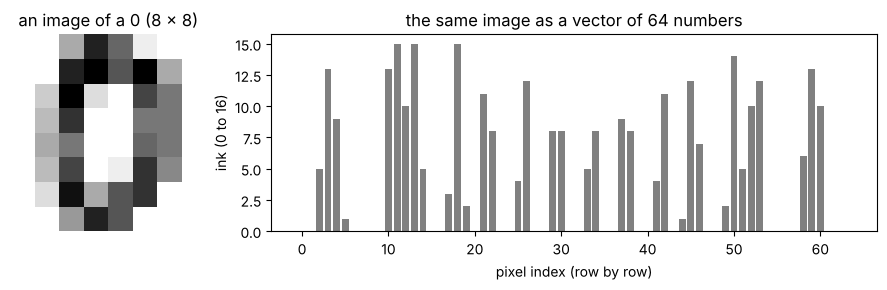

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits, load_wine
from sklearn.model_selection import train_test_split

np.random.seed(0)
np.set_printoptions(precision=3, suppress=True)

marks = np.array([78.0, 85.0, 62.0])                 # one student's marks in Bangla, English and Mathematics
print("one student's marks:", marks, "shape", marks.shape)

vocab = ["data", "model", "learn", "math", "code"]   # a fixed vocabulary
sentences = ["learn math learn code", "data model data", "model learn data math"]
counts = np.array([[s.split().count(w) for w in vocab] for s in sentences])
print("vocabulary:", vocab)
print("word counts, one row per sentence:\n", counts, "\nshape", counts.shape)

digits = load_digits()                               # 1,797 grey images of 8 x 8 pixels, values 0 (white) to 16 (black)
X, y = digits.data, digits.target
print("digits: data matrix X", X.shape, "(rows = images, columns = pixels), labels y", y.shape)
print("first image as an 8 x 8 array:\n", digits.images[0].astype(int))
print("the same image as a vector, first 16 numbers:", X[0, :16].astype(int))

fig, ax = plt.subplots(1, 2, figsize=(9, 3), gridspec_kw={"width_ratios": [1, 3]})
ax[0].imshow(digits.images[0], cmap="gray_r"); ax[0].set_title(f"an image of a {y[0]} (8 x 8)"); ax[0].axis("off")
ax[1].bar(range(64), X[0], color="gray"); ax[1].set_title("the same image as a vector of 64 numbers")
ax[1].set_xlabel("pixel index (row by row)"); ax[1].set_ylabel("ink (0 to 16)")
plt.tight_layout(); plt.show()

### 2. By hand first: dot product, norms, cosine similarity and projection
For vectors $u$ and $v$ with $d$ entries:
- dot product $u \cdot v = \sum_i u_i v_i$;
- norms (lengths): $\|u\|_1 = \sum_i |u_i|$, $\|u\|_2 = \sqrt{\sum_i u_i^2}$, $\|u\|_\infty = \max_i |u_i|$;
- cosine similarity $\cos\theta = \dfrac{u \cdot v}{\|u\|_2 \, \|v\|_2}$, between −1 and 1, and blind to length;
- Euclidean distance $\|u - v\|_2$;
- projection of $a$ onto $b$: $\dfrac{a \cdot b}{b \cdot b}\, b$. What is left over, $a$ minus its projection, is orthogonal (perpendicular) to $b$.

**With pen and paper first**, for $u = (3, 4)$, $v = (4, 3)$, $a = (2, 3)$ and $b = (1, 1)$, compute $u \cdot v$, the three norms of $u$, $\cos(u, v)$, $\|u - v\|_2$ and the projection of $a$ onto $b$. Then run the cell and compare.

In [2]:
u, v = np.array([3.0, 4.0]), np.array([4.0, 3.0])
a, b = np.array([2.0, 3.0]), np.array([1.0, 1.0])

dot = u @ v
l1, l2, linf = np.abs(u).sum(), np.sqrt((u ** 2).sum()), np.abs(u).max()
cos = dot / (np.linalg.norm(u) * np.linalg.norm(v))
proj = (a @ b) / (b @ b) * b
left_over = a - proj
print(f"u . v = {dot}")
print(f"||u||_1 = {l1}, ||u||_2 = {l2}, ||u||_inf = {linf}   (np.linalg.norm: {np.linalg.norm(u, 1)}, {np.linalg.norm(u)}, {np.linalg.norm(u, np.inf)})")
print(f"cos(u, v) = {cos:.4f}, so the angle is {np.degrees(np.arccos(cos)):.2f} degrees")
print(f"||u - v||_2 = {np.linalg.norm(u - v):.4f}  (the square root of 2)")
print(f"projection of a onto b = {proj}, left over = {left_over}, (left over) . b = {left_over @ b}")
assert dot == 24 and (l1, l2, linf) == (7, 5, 4) and abs(cos - 0.96) < 1e-12
assert np.allclose(proj, [2.5, 2.5]) and abs(left_over @ b) < 1e-12

u . v = 24.0
||u||_1 = 7.0, ||u||_2 = 5.0, ||u||_inf = 4.0   (np.linalg.norm: 7.0, 5.0, 4.0)
cos(u, v) = 0.9600, so the angle is 16.26 degrees
||u - v||_2 = 1.4142  (the square root of 2)
projection of a onto b = [2.5 2.5], left over = [-0.5  0.5], (left over) . b = 0.0


### 3. Why normalizing matters
Two different things can be "normalized".
- **The length of a whole vector.** A digit written with lighter ink is the same digit, but every pixel is smaller. Cosine similarity ignores the length; Euclidean distance does not.
- **The scale of each feature.** If one feature is measured in thousands and another in fractions, the large one decides every distance. **Standardizing** subtracts each feature's mean and divides by its standard deviation, both computed on the training rows only.

In [3]:
x0 = X[0]
print(f"cos(x, 0.5 x) = {x0 @ (0.5 * x0) / (np.linalg.norm(x0) * np.linalg.norm(0.5 * x0)):.4f}, "
      f"but ||x - 0.5 x||_2 = {np.linalg.norm(x0 - 0.5 * x0):.2f} (the image's own length is {np.linalg.norm(x0):.2f})")

def nearest_label(X_db, y_db, X_query):
    # squared Euclidean distances between every query and every database row (section 7 explains the trick)
    d2 = (X_query ** 2).sum(1)[:, None] - 2 * X_query @ X_db.T + (X_db ** 2).sum(1)[None, :]
    return y_db[d2.argmin(axis=1)]

wine = load_wine()                                   # 178 wines, 13 chemical measurements, 3 grape types
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(wine.data, wine.target, test_size=0.3, random_state=0, stratify=wine.target)
for name in ["proline", "hue"]:
    j = wine.feature_names.index(name)
    print(f"wine feature {name:8s}: values from {Xw_tr[:, j].min():7.2f} to {Xw_tr[:, j].max():7.2f}")
acc_raw = (nearest_label(Xw_tr, yw_tr, Xw_te) == yw_te).mean()
mu, sd = Xw_tr.mean(0), Xw_tr.std(0)                  # training statistics only
acc_std = (nearest_label((Xw_tr - mu) / sd, yw_tr, (Xw_te - mu) / sd) == yw_te).mean()
print(f"wine, 1-nearest-neighbour test accuracy on {len(yw_te)} wines: raw features {acc_raw:.3f}, standardized {acc_std:.3f}")

cos(x, 0.5 x) = 1.0000, but ||x - 0.5 x||_2 = 27.70 (the image's own length is 55.41)
wine feature proline : values from  278.00 to 1680.00
wine feature hue     : values from    0.48 to    1.42
wine, 1-nearest-neighbour test accuracy on 54 wines: raw features 0.722, standardized 1.000


### 4. Nearest-neighbour search on digits: loops against vectorized NumPy
To classify a query image, find the most similar image in a labelled database and copy its label (the 1-nearest-neighbour rule). We measure similarity with cosine similarity and write the search three ways: pure Python loops, NumPy one query at a time, and all queries at once as one matrix product. **Before running**, estimate by hand how many multiply-adds the all-pairs comparison needs for 360 queries, 1,437 database images and 64 pixels.

database (1437, 64), queries (360, 64); multiply-adds for all pairs: 33,108,480
all three versions find the same neighbours: True
time per query: Python loops 4.452 ms, NumPy per query 0.0154 ms, one matrix product 0.00827 ms
time ratio, Python loops / one matrix product: about 538x
digits, 1-nearest-neighbour test accuracy: cosine 0.981, Euclidean 0.983
  queries with ink x 0.25: cosine 0.981, Euclidean 0.656
  queries with ink x 0.5 : cosine 0.981, Euclidean 0.914
  queries with ink x 2.0 : cosine 0.981, Euclidean 0.942


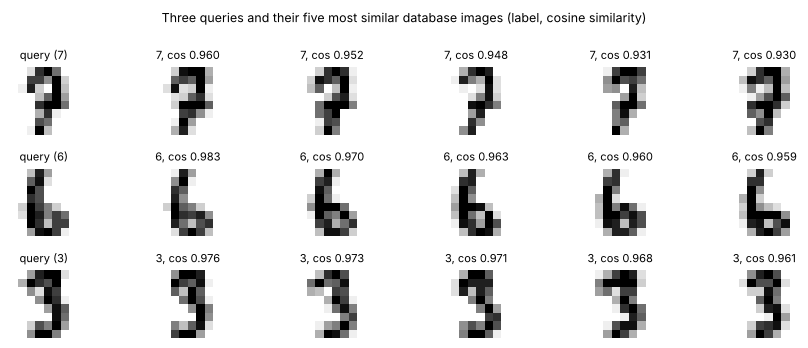

In [4]:
X_db, X_q, y_db, y_q = train_test_split(X, y, test_size=0.2, random_state=0, stratify=y)
print(f"database {X_db.shape}, queries {X_q.shape}; multiply-adds for all pairs: {len(X_q) * len(X_db) * 64:,}")

def nearest_cosine_loops(q, database):
    # pure Python: the index of the database row with the largest cosine similarity to q
    q_norm = sum(t * t for t in q) ** 0.5
    best, best_i = -2.0, -1
    for i, row in enumerate(database):
        dot, row_sq = 0.0, 0.0
        for qt, rt in zip(q, row):
            dot += qt * rt
            row_sq += rt * rt
        c = dot / (q_norm * row_sq ** 0.5)
        if c > best:
            best, best_i = c, i
    return best_i

def nearest_cosine_rows(q, database_unit):
    # NumPy, one query at a time; the database rows already have length 1
    return int(np.argmax(database_unit @ (q / np.linalg.norm(q))))

def nearest_cosine_all(queries, database):
    # NumPy, all queries at once: normalize the rows, then one matrix product gives every cosine
    Q = queries / np.linalg.norm(queries, axis=1, keepdims=True)
    D = database / np.linalg.norm(database, axis=1, keepdims=True)
    return np.argmax(Q @ D.T, axis=1)

n_loop = 20                                          # the loop version is slow, so it only gets 20 queries
db_list, db_unit = X_db.tolist(), X_db / np.linalg.norm(X_db, axis=1, keepdims=True)
t0 = time.perf_counter(); idx_loop = [nearest_cosine_loops(q, db_list) for q in X_q[:n_loop].tolist()]
t_loop = (time.perf_counter() - t0) / n_loop
t0 = time.perf_counter(); idx_rows = [nearest_cosine_rows(q, db_unit) for q in X_q]
t_rows = (time.perf_counter() - t0) / len(X_q)
t0 = time.perf_counter(); idx_all = nearest_cosine_all(X_q, X_db)
t_all = (time.perf_counter() - t0) / len(X_q)
print("all three versions find the same neighbours:", idx_loop == idx_rows[:n_loop] and idx_rows == idx_all.tolist())
print(f"time per query: Python loops {t_loop * 1e3:.3f} ms, NumPy per query {t_rows * 1e3:.4f} ms, one matrix product {t_all * 1e3:.5f} ms")
print(f"time ratio, Python loops / one matrix product: about {t_loop / t_all:,.0f}x")

acc_cos = (y_db[idx_all] == y_q).mean()
acc_euc = (nearest_label(X_db, y_db, X_q) == y_q).mean()
print(f"digits, 1-nearest-neighbour test accuracy: cosine {acc_cos:.3f}, Euclidean {acc_euc:.3f}")
for s in [0.25, 0.5, 2.0]:                           # the same queries written with lighter or darker ink
    a_cos = (y_db[nearest_cosine_all(s * X_q, X_db)] == y_q).mean()
    a_euc = (nearest_label(X_db, y_db, s * X_q) == y_q).mean()
    print(f"  queries with ink x {s:<4}: cosine {a_cos:.3f}, Euclidean {a_euc:.3f}")

S = (X_q / np.linalg.norm(X_q, axis=1, keepdims=True)) @ db_unit.T
fig, ax = plt.subplots(3, 6, figsize=(9, 3.5))
for r, qi in enumerate([0, 1, 2]):
    top5 = np.argsort(-S[qi])[:5]
    ax[r, 0].imshow(X_q[qi].reshape(8, 8), cmap="gray_r"); ax[r, 0].set_title(f"query ({y_q[qi]})", fontsize=8)
    for c, j in enumerate(top5):
        ax[r, c + 1].imshow(X_db[j].reshape(8, 8), cmap="gray_r")
        ax[r, c + 1].set_title(f"{y_db[j]}, cos {S[qi, j]:.3f}", fontsize=8)
for a_ in ax.ravel(): a_.axis("off")
plt.suptitle("Three queries and their five most similar database images (label, cosine similarity)", fontsize=9)
plt.tight_layout(); plt.show()

### 5. A matrix is a function: what 2 × 2 matrices do to the plane
A matrix $A$ sends a vector $x$ to $Ax$. The **columns** of $A$ are where the basis vectors $e_1 = (1, 0)$ and $e_2 = (0, 1)$ land, and every other point follows, because $A(x_1 e_1 + x_2 e_2) = x_1 (A e_1) + x_2 (A e_2)$. The unit square becomes a parallelogram whose area is $|\det A|$.

**By hand first:** for $M = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}$, where do $(1, 0)$, $(0, 1)$ and $(1, 1)$ go, and what is the area of the image of the unit square?

M e1 = [2. 1.]  M e2 = [1. 2.]  M (1, 1) = [3. 3.]
rotation R (90 degrees)  det =  1.00, area of the image of the unit square = 1.00
scaling D                det =  0.75, area of the image of the unit square = 0.75
shear S                  det =  1.00, area of the image of the unit square = 1.00
symmetric M              det =  3.00, area of the image of the unit square = 3.00


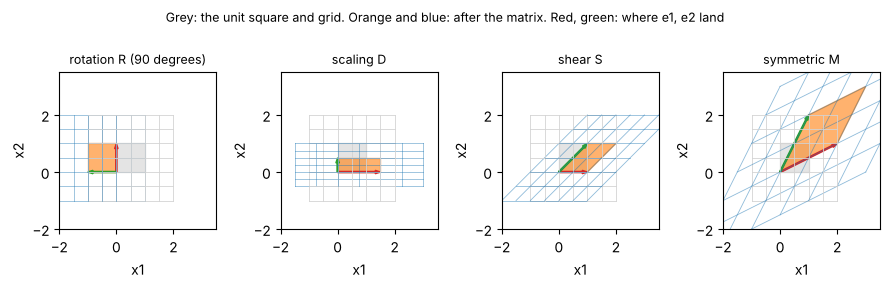

In [5]:
mats = {
    "rotation R (90 degrees)": np.array([[0.0, -1.0], [1.0, 0.0]]),
    "scaling D": np.array([[1.5, 0.0], [0.0, 0.5]]),
    "shear S": np.array([[1.0, 1.0], [0.0, 1.0]]),
    "symmetric M": np.array([[2.0, 1.0], [1.0, 2.0]]),
}
square = np.array([[0, 1, 1, 0], [0, 0, 1, 1]], dtype=float)      # corners of the unit square, as columns

def polygon_area(P):
    # shoelace formula for the polygon whose corners are the columns of P
    x_, y_ = P
    return 0.5 * abs(x_ @ np.roll(y_, -1) - y_ @ np.roll(x_, -1))

M = mats["symmetric M"]
print("M e1 =", M @ [1, 0], " M e2 =", M @ [0, 1], " M (1, 1) =", M @ [1, 1])
for name, A in mats.items():
    print(f"{name:24s} det = {np.linalg.det(A):5.2f}, area of the image of the unit square = {polygon_area(A @ square):.2f}")

def draw(ax, A, title):
    for t in np.linspace(-1, 2, 7):                                # grid lines, before and after
        for line in (np.array([[t, t], [-1, 2]]), np.array([[-1, 2], [t, t]])):
            ax.plot(*line, color="lightgray", lw=0.6)
            ax.plot(*(A @ line), color="tab:blue", lw=0.6, alpha=0.5)
    ax.fill(*square, color="lightgray", alpha=0.6)
    ax.fill(*(A @ square), color="tab:orange", alpha=0.6)
    ax.arrow(0, 0, *A[:, 0], color="tab:red", width=0.04, length_includes_head=True)
    ax.arrow(0, 0, *A[:, 1], color="tab:green", width=0.04, length_includes_head=True)
    ax.set_xlim(-2, 3.5); ax.set_ylim(-2, 3.5); ax.set_aspect("equal")
    ax.set_title(title, fontsize=9); ax.set_xlabel("x1"); ax.set_ylabel("x2")

fig, ax = plt.subplots(1, 4, figsize=(9, 2.8))
for a_, (name, A) in zip(ax, mats.items()):
    draw(a_, A, name)
plt.suptitle("Grey: the unit square and grid. Orange and blue: after the matrix. Red, green: where e1, e2 land", fontsize=9)
plt.tight_layout(); plt.show()

### 6. Composition: $AB$ means "first $B$, then $A$", and $AB \ne BA$
$(AB)x = A(Bx)$: the matrix product is the function "apply $B$, then apply $A$". Order matters. **By hand first:** with the rotation $R$ and the shear $S$ from section 5, compute $RS$ and $SR$, and where each sends $(1, 0)$.

RS =
 [[ 0. -1.]
 [ 1.  1.]] 
SR =
 [[ 1. -1.]
 [ 1.  0.]]
RS e1 = [0. 1.]   SR e1 = [1. 1.]
(RS) x equals R (S x): True   RS equals SR: False
two diagonal scalings commute: True


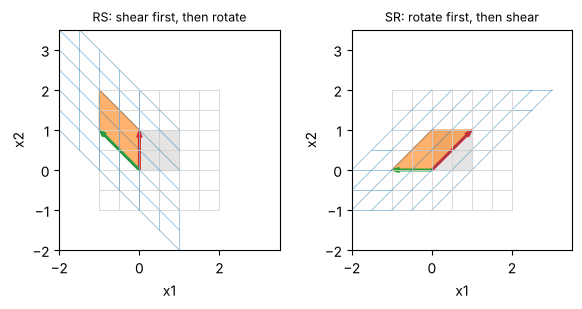

In [6]:
R, Sh = mats["rotation R (90 degrees)"], mats["shear S"]
RS, SR = R @ Sh, Sh @ R
print("RS =\n", RS, "\nSR =\n", SR)
print("RS e1 =", RS @ [1, 0], "  SR e1 =", SR @ [1, 0])
rng = np.random.default_rng(0)
x_test = rng.standard_normal(2)
print("(RS) x equals R (S x):", np.allclose(RS @ x_test, R @ (Sh @ x_test)), "  RS equals SR:", np.allclose(RS, SR))
D = mats["scaling D"]
print("two diagonal scalings commute:", np.allclose(D @ np.diag([3.0, 2.0]), np.diag([3.0, 2.0]) @ D))

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
draw(ax[0], RS, "RS: shear first, then rotate")
draw(ax[1], SR, "SR: rotate first, then shear")
plt.tight_layout(); plt.show()

### 7. The cost of operations, and broadcasting
- An $n \times n$ matrix times a vector costs $n^2$ multiply-adds; a matrix times a matrix costs $n^3$. So for $ABx$, compute $A(Bx)$ (two matrix–vector products, $2n^2$), not $(AB)x$ ($n^3 + n^2$).
- **Broadcasting:** NumPy compares shapes from the right; two sizes fit if they are equal or one of them is 1, and the size-1 axis is repeated. Shapes (1797, 64) and (64,) give (1797, 64): that is how `X - X.mean(axis=0)` centres every row. Broadcasting is also behind the distance trick $\|q - d\|^2 = \|q\|^2 - 2\, q \cdot d + \|d\|^2$ used above.
- The same rule causes a classic silent bug: shapes (n,) and (n, 1) broadcast to (n, n). Course 15 session 3 drills shapes and broadcasting.

In [7]:
n = 1000
A_big, B_big, x_big = rng.standard_normal((n, n)), rng.standard_normal((n, n)), rng.standard_normal(n)
t0 = time.perf_counter(); r1 = (A_big @ B_big) @ x_big; t1 = time.perf_counter() - t0
t0 = time.perf_counter(); r2 = A_big @ (B_big @ x_big); t2 = time.perf_counter() - t0
print(f"(AB)x: about {n**3 + n**2:.1e} multiply-adds, time {t1 * 1e3:.1f} ms;  A(Bx): {2 * n**2:.1e} multiply-adds, time {t2 * 1e3:.2f} ms")
print("same answer up to rounding:", np.allclose(r1, r2))

Xc = X - X.mean(axis=0)                                            # (1797, 64) - (64,) -> (1797, 64)
print("shapes:", X.shape, "-", X.mean(axis=0).shape, "->", Xc.shape, "; column means after centring are 0:", np.allclose(Xc.mean(0), 0))
q5, d7 = X_q[:5], X_db[:7]
d2_trick = (q5 ** 2).sum(1)[:, None] - 2 * q5 @ d7.T + (d7 ** 2).sum(1)[None, :]   # (5,1) - (5,7) + (1,7) -> (5,7)
d2_direct = ((q5[:, None, :] - d7[None, :, :]) ** 2).sum(-1)                        # (5,1,64) - (1,7,64) -> (5,7,64)
print("distance trick equals the direct (5, 7, 64) version:", np.allclose(d2_trick, d2_direct), d2_trick.shape)

y_true = np.array([1.0, 2.0, 3.0, 4.0])
y_pred = np.array([[1.1], [2.1], [2.9], [4.2]])                  # a model output of shape (4, 1)
print("y_true", y_true.shape, "- y_pred", y_pred.shape, "->", (y_true - y_pred).shape, "(silently wrong)")
print(f"mean squared error, buggy: {np.mean((y_true - y_pred) ** 2):.3f};  correct: {np.mean((y_true - y_pred.ravel()) ** 2):.3f}")

(AB)x: about 1.0e+09 multiply-adds, time 10.4 ms;  A(Bx): 2.0e+06 multiply-adds, time 0.56 ms
same answer up to rounding: True
shapes: (1797, 64) - (64,) -> (1797, 64) ; column means after centring are 0: True
distance trick equals the direct (5, 7, 64) version: True (5, 7)
y_true (4,) - y_pred (4, 1) -> (4, 4) (silently wrong)
mean squared error, buggy: 2.543;  correct: 0.018


### 8. TODO
1. Complete `knn_predict`: the majority label among the $k$ most similar database images (cosine similarity). Report the test accuracy for $k$ = 1, 3 and 5.
2. Complete `nearest_l1`: 1-nearest neighbour with the L1 distance $\sum_i |q_i - d_i|$, vectorized with broadcasting. Compare its accuracy with cosine and Euclidean.

In [8]:
# TODO: k-nearest neighbours with a majority vote, and 1-NN with the L1 distance
def knn_predict(queries, database, labels, k):
    return None      # replace: cosine similarities, the k largest per row (np.argsort), then np.bincount(...).argmax()

def nearest_l1(queries, database, labels):
    return None      # replace: np.abs(queries[:, None, :] - database[None, :, :]).sum(-1), then argmin per row

pred = knn_predict(X_q, X_db, y_db, k=3)
print("not done yet" if pred is None else f"3-NN cosine accuracy: {(pred == y_q).mean():.3f}")
pred = nearest_l1(X_q, X_db, y_db)
print("not done yet" if pred is None else f"1-NN L1 accuracy: {(pred == y_q).mean():.3f}")

not done yet
not done yet


### 9. The same search on MNIST (NOT RUN here)
MNIST has 70,000 images of 28 × 28 = 784 pixels. All 10,000 × 60,000 cosine similarities at once would need 4.8 GB in float64, so the search runs in blocks of 1,000 queries.

In [ ]:
# NOT RUN: needs a download of MNIST (70,000 images) from OpenML through fetch_openml.
import numpy as np
from sklearn.datasets import fetch_openml
X_m, y_m = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True)
X_m, y_m = X_m.astype(np.float32), y_m.astype(int)
db, q = X_m[:60000], X_m[60000:]                                    # the usual split: 60,000 database, 10,000 queries
db_unit = db / np.linalg.norm(db, axis=1, keepdims=True)
q_unit = q / np.linalg.norm(q, axis=1, keepdims=True)
pred = np.empty(len(q), dtype=int)
for start in range(0, len(q), 1000):                                 # 1,000 x 60,000 float32 similarities = 240 MB per block
    pred[start:start + 1000] = y_m[:60000][np.argmax(q_unit[start:start + 1000] @ db_unit.T, axis=1)]
print(f"MNIST 1-NN accuracy with cosine similarity: {(pred == y_m[60000:]).mean():.4f}")

### What to notice
- **The hand calculations matched (section 2):** $u \cdot v = 24$, norms 7, 5 and 4, $\cos(u, v) = 0.96$ (an angle of 16.26°), and the projection of $a$ onto $b$ is (2.5, 2.5), with a left-over part (−0.5, 0.5) whose dot product with $b$ is exactly 0.
- **Feature scales decided the wine result (section 3).** Proline runs from 278 to 1,680 and hue from 0.48 to 1.42, so raw distances are almost all proline. One-nearest-neighbour accuracy on 54 test wines rose from 0.722 to 1.000 after standardizing.
- **Vectorizing changed the time, not the answer (section 4).** All three searches found the same neighbours. In the saved run the Python loops took 4.45 ms per query and one matrix product 0.008 ms per query, a ratio of about 540; timings change from run to run and machine to machine.
- **Cosine similarity did not beat Euclidean distance on the original digits** (0.981 against 0.983): these images all carry similar amounts of ink, so length holds little extra information. It mattered once the ink changed: with queries at 0.25 times the ink, Euclidean accuracy fell to 0.656 while cosine stayed at 0.981.
- **Matrices as functions (sections 5–6).** The area of the image of the unit square equalled $|\det A|$ for all four matrices (1, 0.75, 1 and 3). $RS$ and $SR$ are different matrices: $RS$ sends (1, 0) to (0, 1), $SR$ sends it to (1, 1).
- **Order of operations is cost (section 7).** $(AB)x$ took 10.4 ms and $A(Bx)$ 0.56 ms for $n = 1000$ in the saved run, with the same result. The shape bug gave a mean squared error of 2.543 instead of 0.018 without any error message.
- These are small datasets on one CPU. The ideas carry over to large data, where the matrix-product search is run in blocks (section 9) or replaced by approximate search libraries.